## Data Understanding 
### Objectif
Comprendre la structure du dataset avant toute transformation : source, dimensions, variables, types, valeurs manquantes, doublons et variable cible.

**Important :** ce projet est un prototype pédagogique basé sur des données synthétiques. Les prédictions ne constituent pas un diagnostic médical.

## 1. Importer les bibliothèques

Nous utilisons `pandas` pour manipuler les données et `matplotlib` / `seaborn` pour les visualisations exploratoires.

In [156]:
from pathlib import Path
import pandas as pd
import time
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    StratifiedKFold,
    RandomizedSearchCV
    )
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import joblib




pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

# Project paths
DATA_RAW_DIR = Path(r"..\data\raw") 
print("Raw data directory:", DATA_RAW_DIR)
print("Raw directory exists:", DATA_RAW_DIR.exists())

Raw data directory: ..\data\raw
Raw directory exists: True


## 2. Repérer le fichier du dataset

Cette cellule liste les fichiers présents dans `data/raw/`. Vérifie le nom du CSV avant de le charger. Si plusieurs fichiers apparaissent, sélectionne explicitement le bon fichier.

In [157]:
csv_files = sorted(DATA_RAW_DIR.glob('*.csv')) if DATA_RAW_DIR.exists() else []

if not csv_files:
    print('Aucun fichier CSV trouvé dans data/raw/.')
    print('Place le dataset Kaggle dans ce dossier, puis relance cette cellule.')
else:
    for file in csv_files:
        print(f'- {file.name} ({file.stat().st_size:,} bytes)')

- student_mental_health.csv (157,026 bytes)


## 3. Charger le dataset

Après avoir vérifié le fichier listé ci-dessus, renseigne son nom exact dans `DATASET_FILENAME`. Ne modifie pas le fichier original : cette étape sert uniquement à le lire.

In [ ]:
DATASET_PATH =csv_files[0]

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f'Fichier introuvable : {DATASET_PATH}\n'
        'Vérifie DATASET_FILENAME et le dossier data/raw/.'
    )
print(csv_files[0])
df = pd.read_csv(DATASET_PATH)
print('Dataset chargé avec succès.')
print('Source locale :', DATASET_PATH)
print('Dimensions :', df.shape)

..\data\raw\student_mental_health.csv
Dataset chargé avec succès.
Source locale : ..\data\raw\student_mental_health.csv
Dimensions : (2000, 17)


## 4. Aperçu général

Afficher les premières et dernières lignes permet de vérifier que le fichier a été interprété correctement.

In [161]:
display(df.head())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [162]:
display(df.tail())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


## 5. Structure et types des variables

`info()` donne le nombre de valeurs non nulles et les types détectés. `dtypes` permet de consulter les types colonne par colonne.

In [163]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [164]:
display(df.dtypes.rename('data_type').to_frame())

,data_type
Student_ID,str
Age,int64
Gender,str
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,str


## 6. Première synthèse descriptive

Cette synthèse décrit les variables numériques. Les variables catégorielles seront examinées séparément dans les étapes suivantes.

In [165]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


## 7. Contrôles initiaux de qualité

Nous mesurons les valeurs manquantes et les lignes dupliquées sans encore supprimer ni modifier aucune donnée.

In [109]:
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(2)
}).sort_values('missing_percent', ascending=False)

display(missing_summary)
print('Nombre de lignes dupliquées :', df.duplicated().sum())

,missing_count,missing_percent
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90
Student_ID,0,0.00
Age,0,0.00
Screen_Time_Hours,0,0.00


Nombre de lignes dupliquées : 0


## 8. Identifier la variable cible

La cible attendue dans ce projet est `Mental_Health_Risk`. Vérifie d'abord qu'elle existe dans le dataset et observe ses modalités. Ne suppose pas la distribution avant d'avoir exécuté cette cellule.

In [110]:
TARGET_COLUMN = 'Mental_Health_Risk'

if TARGET_COLUMN not in df.columns:
    print(f'Attention : la colonne cible {TARGET_COLUMN!r} est absente.')
    print('Colonnes disponibles :', df.columns.tolist())
else:
    print('Répartition de la cible :')
    display(df[TARGET_COLUMN].value_counts(dropna=False).to_frame('count'))
    print('\nRépartition en pourcentage :')
    display((df[TARGET_COLUMN].value_counts(normalize=True, dropna=False) * 100)
            .round(2).to_frame('percentage'))

Répartition de la cible :


,count
Mental_Health_Risk,
High,680
Medium,660
Low,660



Répartition en pourcentage :


,percentage
Mental_Health_Risk,
High,34.0
Medium,33.0
Low,33.0


## 9. Identification des variables numériques, catégorielles et identifiantes

Nous classons les colonnes selon leur nature.

### Numeric Variables
Variables quantitatives pouvant être étudiées avec des statistiques numériques.

### Categorical Variables
Variables représentant des catégories ou des modalités.

### Identifier Variables
Variables permettant d'identifier une observation, comme `Student_ID`.

Les identifiants ne sont pas considérés comme des caractéristiques explicatives pertinentes pour notre analyse statistique.

La variable cible est également exclue des Features.

In [ ]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

possible_id_columns = [
    col for col in df.columns
    if col.lower() in ["id", "student_id"]
    or col.lower().endswith("_id")
]


numeric_features = [
    col for col in numeric_columns
    if col not in possible_id_columns
    and col != TARGET_COLUMN
]

categorical_features = [
    col for col in categorical_columns
    if col not in possible_id_columns
    and col != TARGET_COLUMN
]


print("Numeric columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\nIdentifier columns:")
print(possible_id_columns)

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric columns:
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Categorical columns:
['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']

Identifier columns:
['Student_ID']

Numeric features:
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Categorical features:
['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


C:\Users\Youcode\AppData\Local\Temp\ipykernel_16176\199284513.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


## 11. Analyse univariée — Variables numériques

L'analyse univariée permet d'étudier chaque variable indépendamment.

Nous utilisons des histogrammes pour visualiser les distributions des variables numériques.

L'option `kde=True` ajoute une estimation de la densité de probabilité.

Cette analyse permet d'observer :

- La concentration des observations.
- La forme des distributions.
- Les éventuelles asymétries.
- Les valeurs qui semblent inhabituelles.

Les graphiques sont organisés dans une grille pour faciliter leur comparaison.

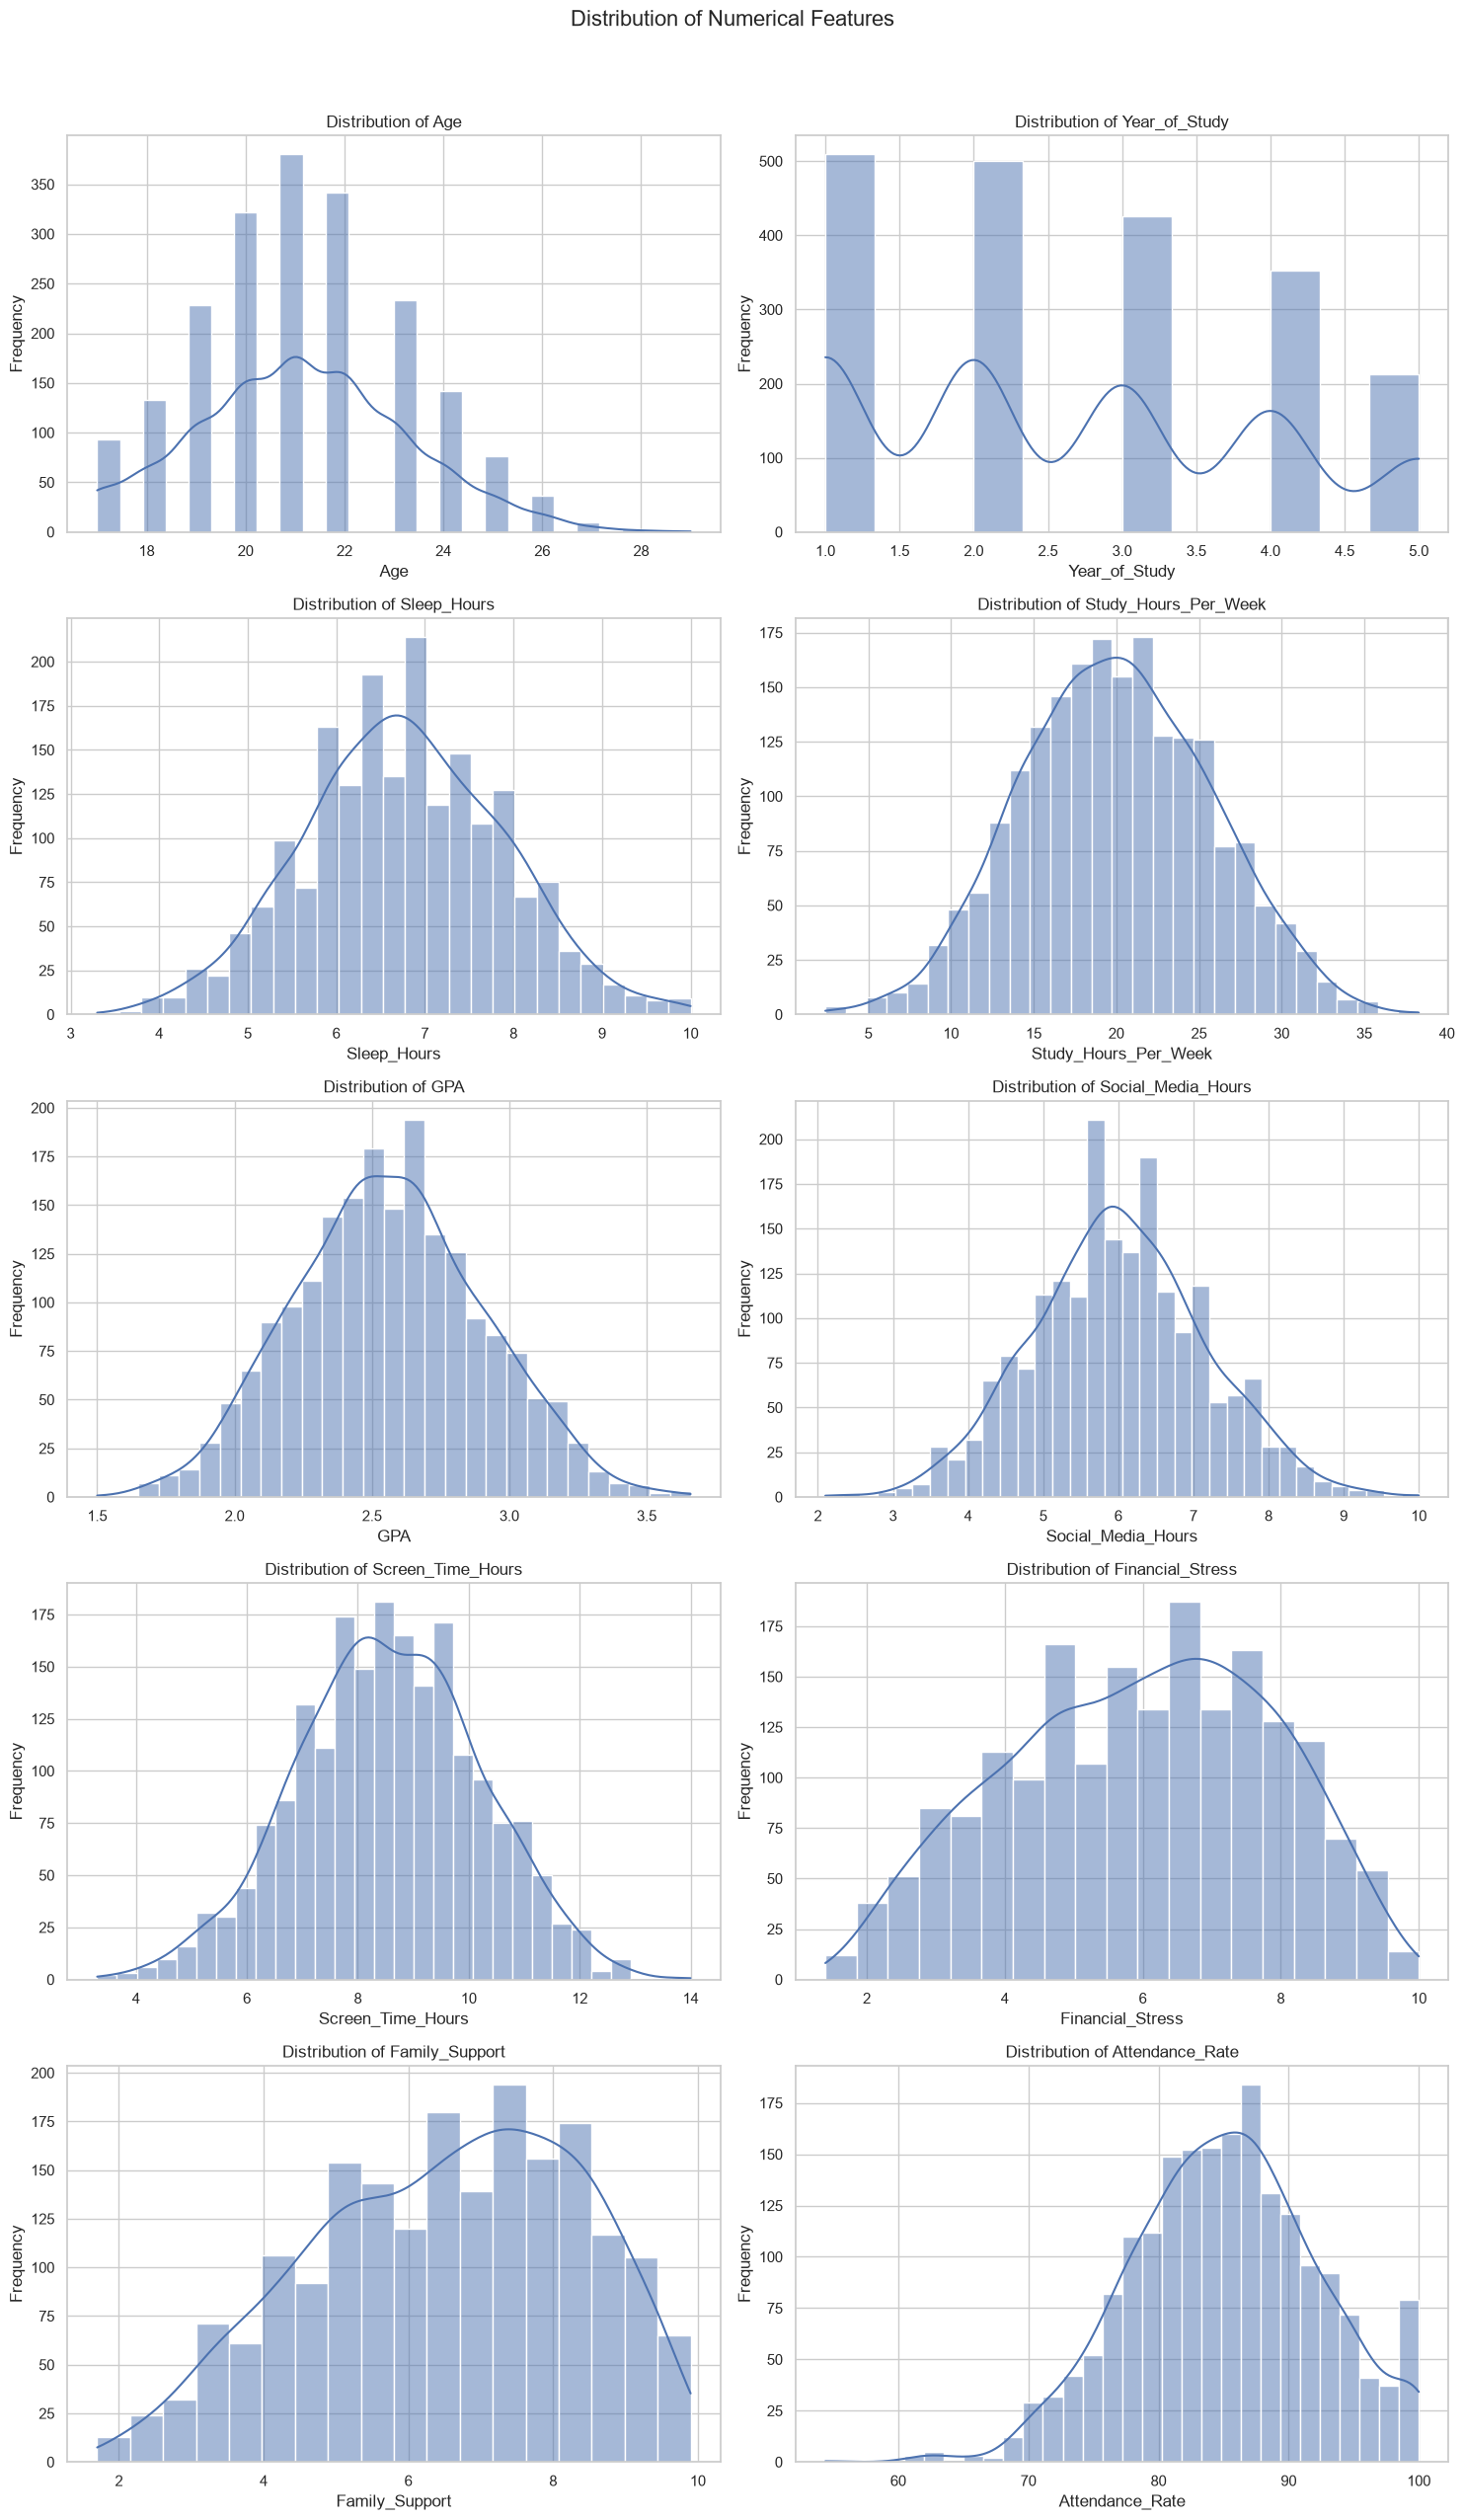

In [ ]:
if not numeric_features:
    print("No numerical features available for visualization.")

else:
    n_cols = 2
    n_rows = math.ceil(len(numeric_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(15, 5 * n_rows),
        squeeze=False
    )

    axes = axes.flatten()

    for i, column in enumerate(numeric_features):

        sns.histplot(
            data=df,
            x=column,
            kde=True,
            ax=axes[i]
        )

        axes[i].set_title(f"Distribution of {column}")
        axes[i].set_xlabel(column)
        axes[i].set_ylabel("Frequency")

    for j in range(len(numeric_features), len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Distribution of Numerical Features",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## 12. Analyse univariée — Variables catégorielles

Nous utilisons des diagrammes en barres pour observer la fréquence de chaque catégorie.

Cette analyse permet de :

- Identifier les catégories les plus fréquentes.
- Comparer les effectifs.
- Détecter les catégories rares.
- Observer les éventuelles valeurs manquantes.

Nous limitons l'affichage aux vingt catégories les plus fréquentes pour éviter de surcharger les graphiques.

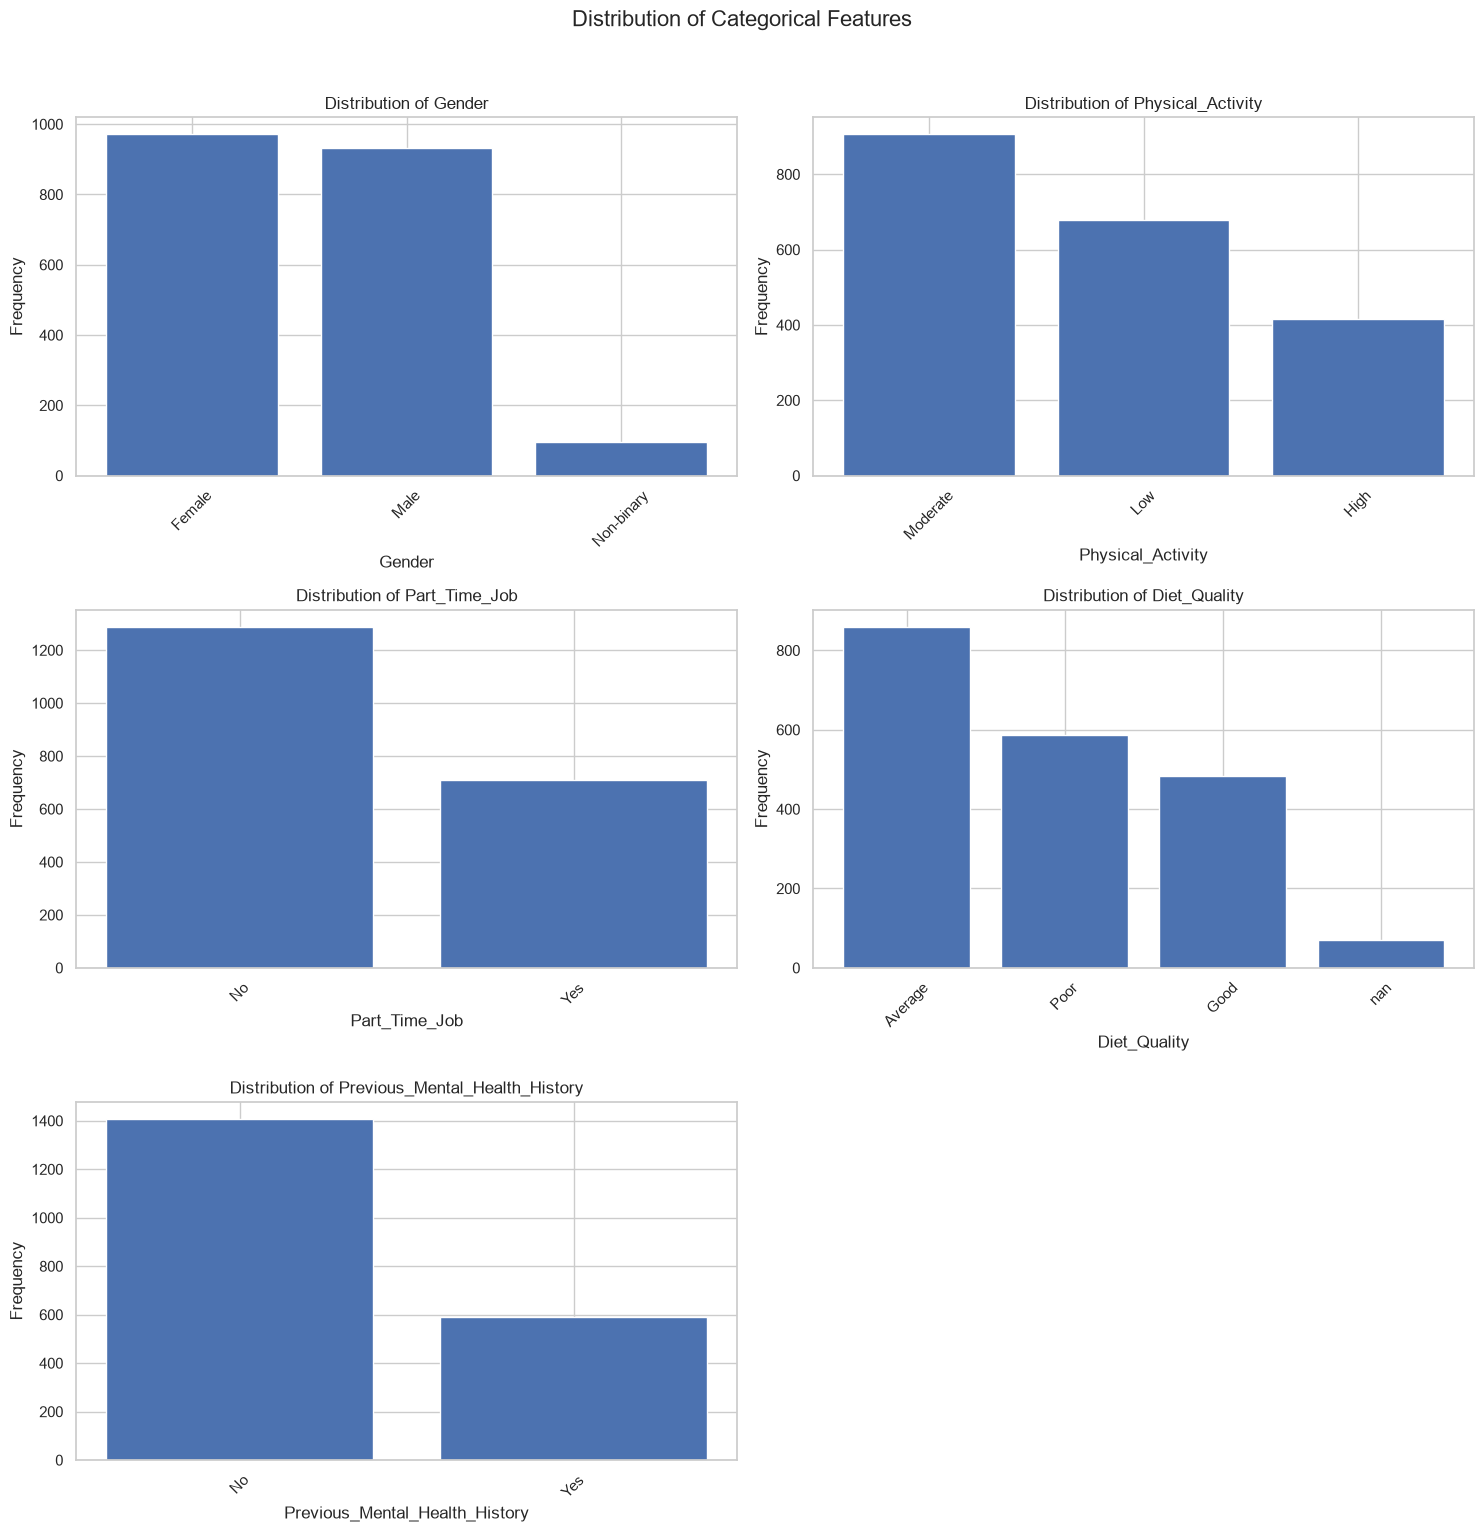

In [ ]:
if not categorical_features:
    print("No categorical features available for visualization.")

else:
    n_cols = 2
    n_rows = math.ceil(len(categorical_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(15, 5 * n_rows),
        squeeze=False
    )

    axes = axes.flatten()

    for i, column in enumerate(categorical_features):

        counts = df[column].value_counts(
            dropna=False
        ).head(20)

        labels = [str(x) for x in counts.index]

        axes[i].bar(
            labels,
            counts.values
        )

        axes[i].set_title(f"Distribution of {column}")
        axes[i].set_xlabel(column)
        axes[i].set_ylabel("Frequency")

        axes[i].tick_params(
            axis="x",
            rotation=45
        )

    for j in range(len(categorical_features), len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Distribution of Categorical Features",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## 13. Visualisation de la variable cible

Nous représentons la distribution de `Mental_Health_Risk` avec un diagramme en barres.

Cette visualisation permet de comparer les effectifs des classes Low, Medium et High.

L'objectif est de détecter un éventuel déséquilibre des classes, qui devra être pris en compte lors de l'entraînement et de l'évaluation des modèles de classification.

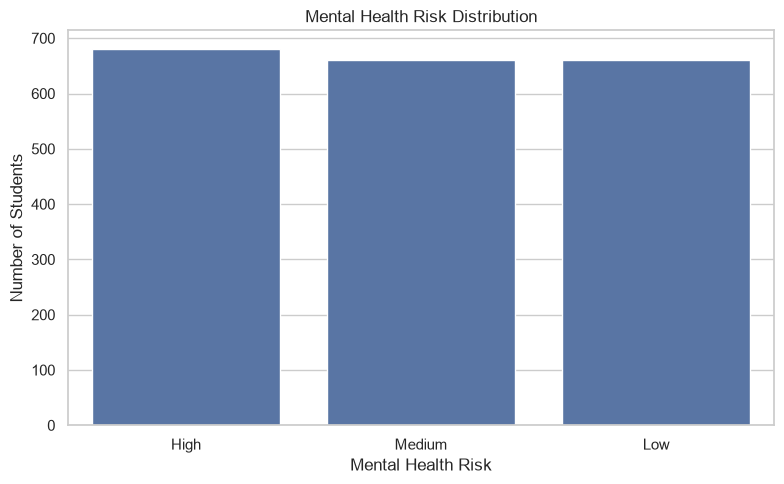

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=TARGET_COLUMN,
    order=df[TARGET_COLUMN].value_counts().index
)

plt.title("Mental Health Risk Distribution")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

## 14. Analyse bivariée — Variables numériques et cible

Nous utilisons des Boxplots pour comparer les distributions des variables numériques selon les catégories de `Mental_Health_Risk`.

Les Boxplots permettent d'observer :

- La médiane.
- Les quartiles.
- L'étendue interquartile.
- Les observations potentiellement extrêmes.

Cette comparaison permet d'identifier des différences de distribution entre les classes.

Une association observée ne signifie pas nécessairement une relation de causalité.

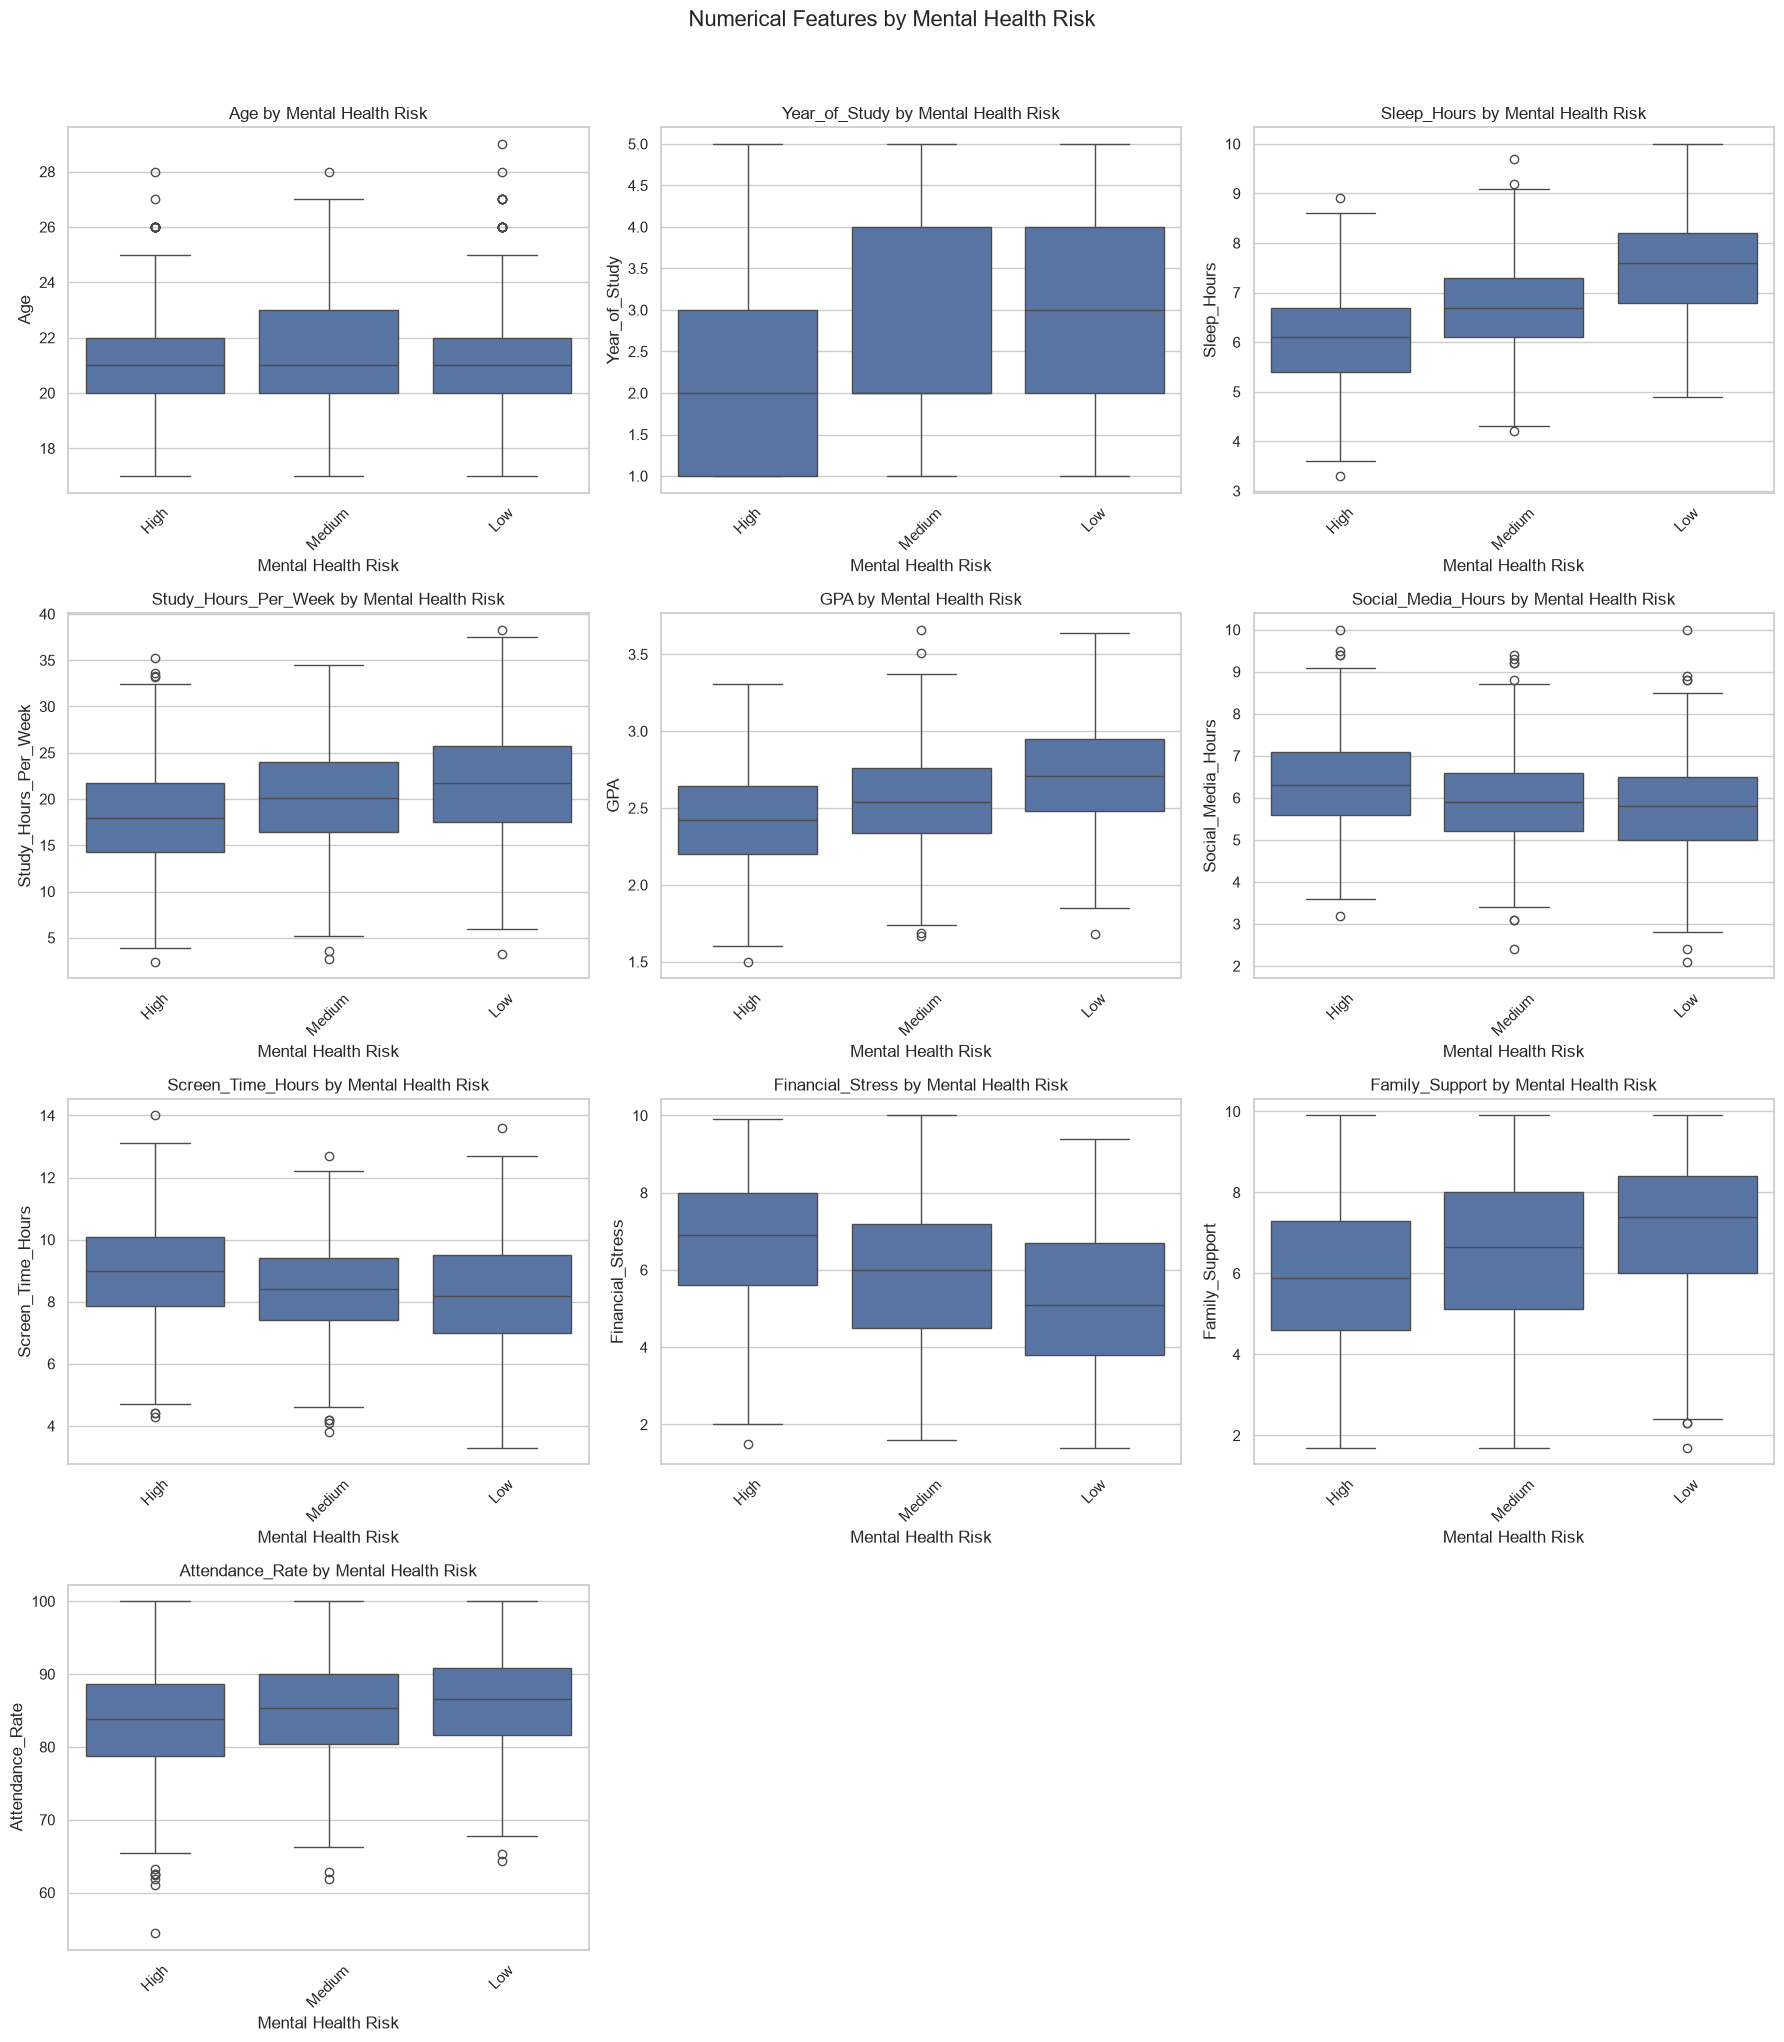

In [ ]:
if not numeric_features:
    print("No numerical features available for boxplots.")

else:
    n_cols = 3
    n_rows = math.ceil(len(numeric_features) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(18, 5 * n_rows),
        squeeze=False
    )

    axes = axes.flatten()

    for i, column in enumerate(numeric_features):

        plot_data = df[[TARGET_COLUMN, column]].dropna()

        sns.boxplot(
            data=plot_data,
            x=TARGET_COLUMN,
            y=column,
            ax=axes[i]
        )

        axes[i].set_title(
            f"{column} by Mental Health Risk"
        )

        axes[i].set_xlabel("Mental Health Risk")
        axes[i].set_ylabel(column)

        axes[i].tick_params(
            axis="x",
            rotation=45
        )

    for j in range(len(numeric_features), len(axes)):
        fig.delaxes(axes[j])

    fig.suptitle(
        "Numerical Features by Mental Health Risk",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

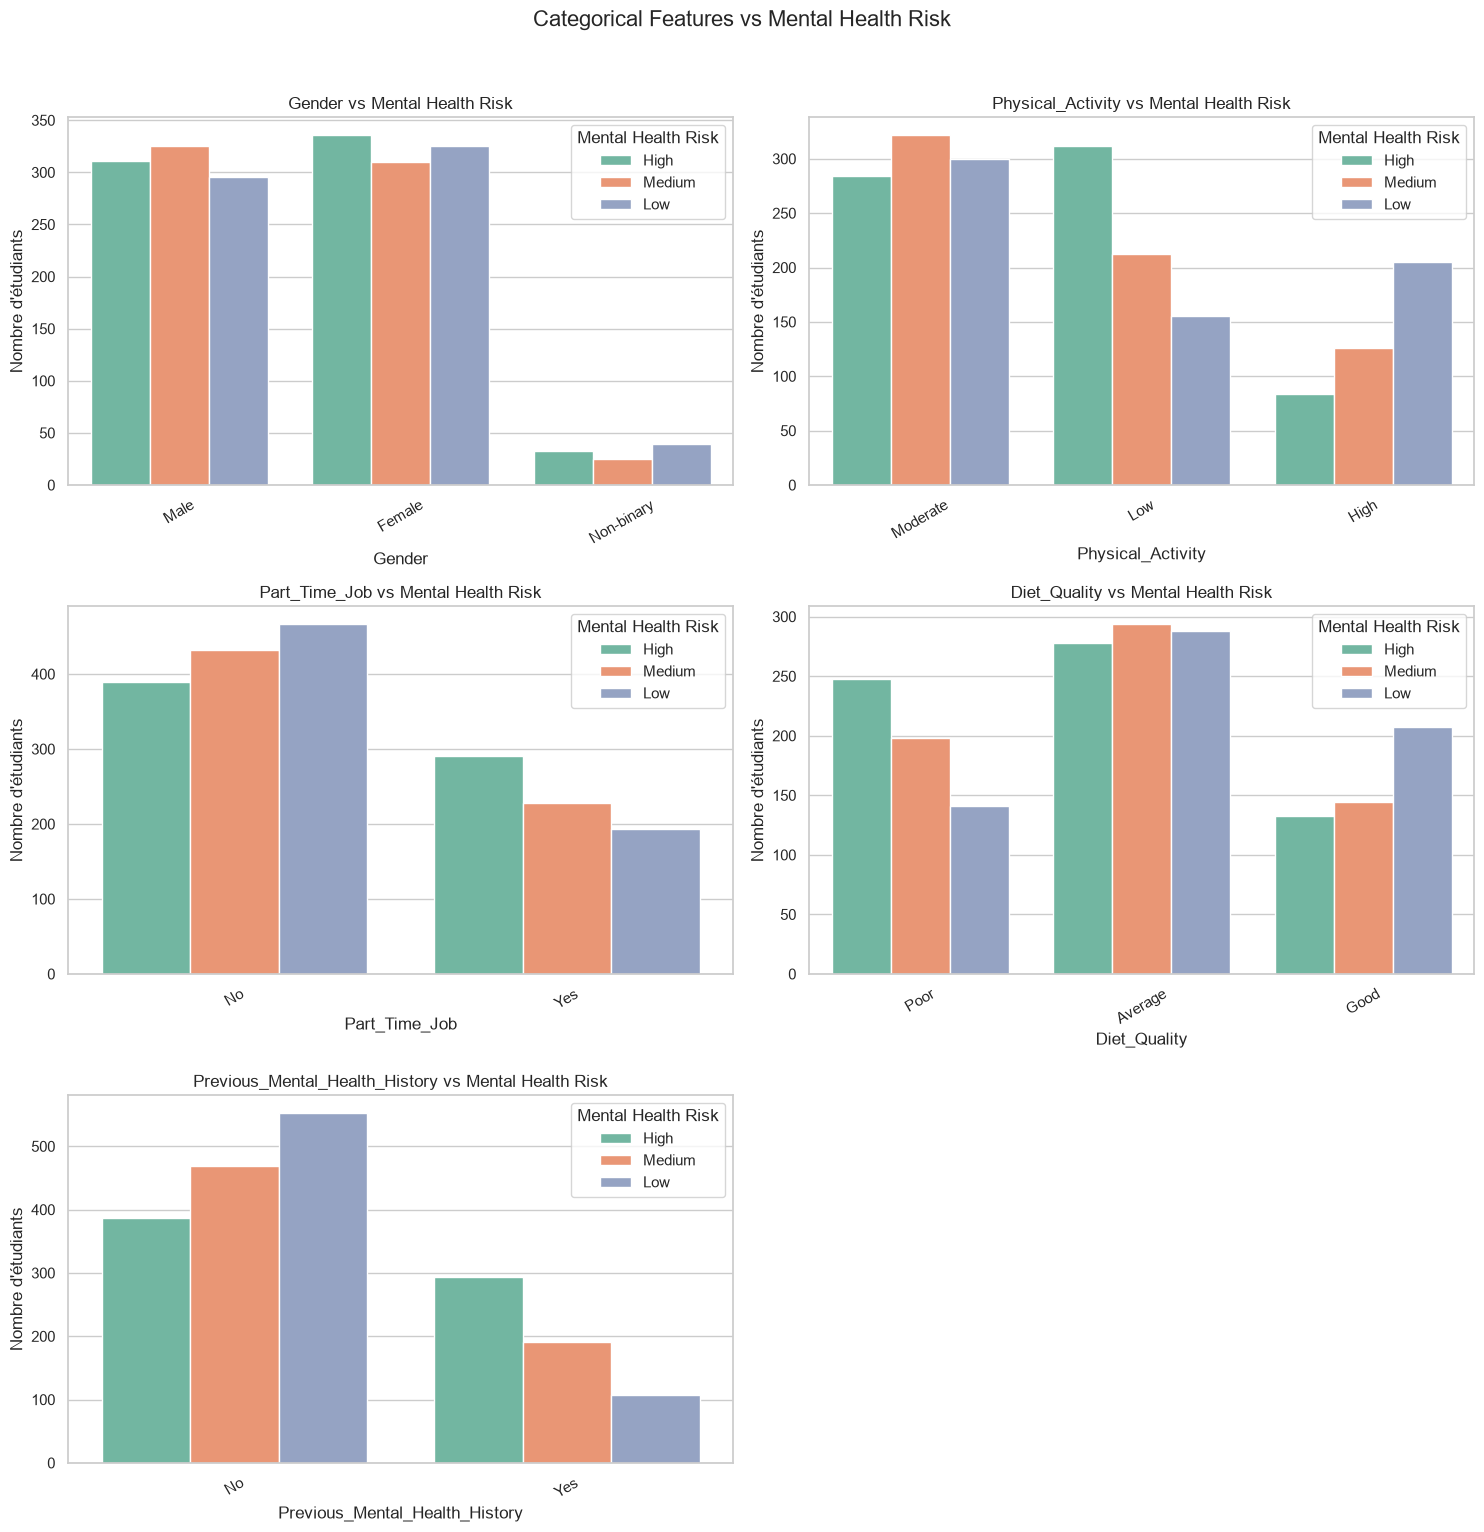

In [167]:
categorical_data = df[categorical_features + [TARGET_COLUMN]].copy()

n_cols = 2
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 5 * n_rows),
    squeeze=False
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    sns.countplot(
        data=categorical_data,
        x=feature,
        hue=target,
        palette="Set2",
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Mental Health Risk")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Nombre d'étudiants")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].legend(title="Mental Health Risk")

for j in range(len(categorical_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Categorical Features vs Mental Health Risk",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


## 15. Analyse des corrélations

Nous calculons la matrice de corrélation de Pearson entre les variables numériques.

Les coefficients varient entre -1 et +1 :

- +1 : corrélation linéaire positive parfaite.
- -1 : corrélation linéaire négative parfaite.
- 0 : absence de corrélation linéaire.

Cette analyse permet d'identifier les relations linéaires entre les variables numériques.

La corrélation ne démontre pas une relation de causalité.

In [ ]:
if len(numeric_features) < 2:
    print(
        "At least two numerical features are required "
        "to calculate a correlation matrix."
    )

else:
    correlation_matrix = df[
        numeric_features
    ].corr(method="pearson")

    display(
        correlation_matrix.round(2)
    )

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Age,1.00,0.00,-0.01,-0.01,0.00,-0.01,-0.01,0.00,-0.01,-0.01
Year_of_Study,0.00,1.00,0.03,0.70,0.34,-0.35,-0.24,-0.01,0.01,0.08
Sleep_Hours,-0.01,0.03,1.00,0.03,0.25,0.00,0.02,0.02,0.01,0.08
Study_Hours_Per_Week,-0.01,0.70,0.03,1.00,0.49,-0.50,-0.33,-0.03,0.04,0.14
GPA,0.00,0.34,0.25,0.49,1.00,-0.23,-0.16,0.00,0.01,0.29
Social_Media_Hours,-0.01,-0.35,0.00,-0.50,-0.23,1.00,0.68,-0.01,-0.06,-0.07
Screen_Time_Hours,-0.01,-0.24,0.02,-0.33,-0.16,0.68,1.00,-0.00,-0.04,-0.06
Financial_Stress,0.00,-0.01,0.02,-0.03,0.00,-0.01,-0.00,1.00,0.05,-0.00
Family_Support,-0.01,0.01,0.01,0.04,0.01,-0.06,-0.04,0.05,1.00,0.00
Attendance_Rate,-0.01,0.08,0.08,0.14,0.29,-0.07,-0.06,-0.00,0.00,1.00


## 16. Visualisation de la matrice de corrélation

Nous utilisons une Heatmap pour représenter graphiquement les coefficients de corrélation.

Les couleurs facilitent l'identification des relations positives et négatives entre les variables.

L'option `annot=True` affiche les coefficients directement dans les cellules.

Cette visualisation complète l'analyse statistique de la matrice de corrélation.

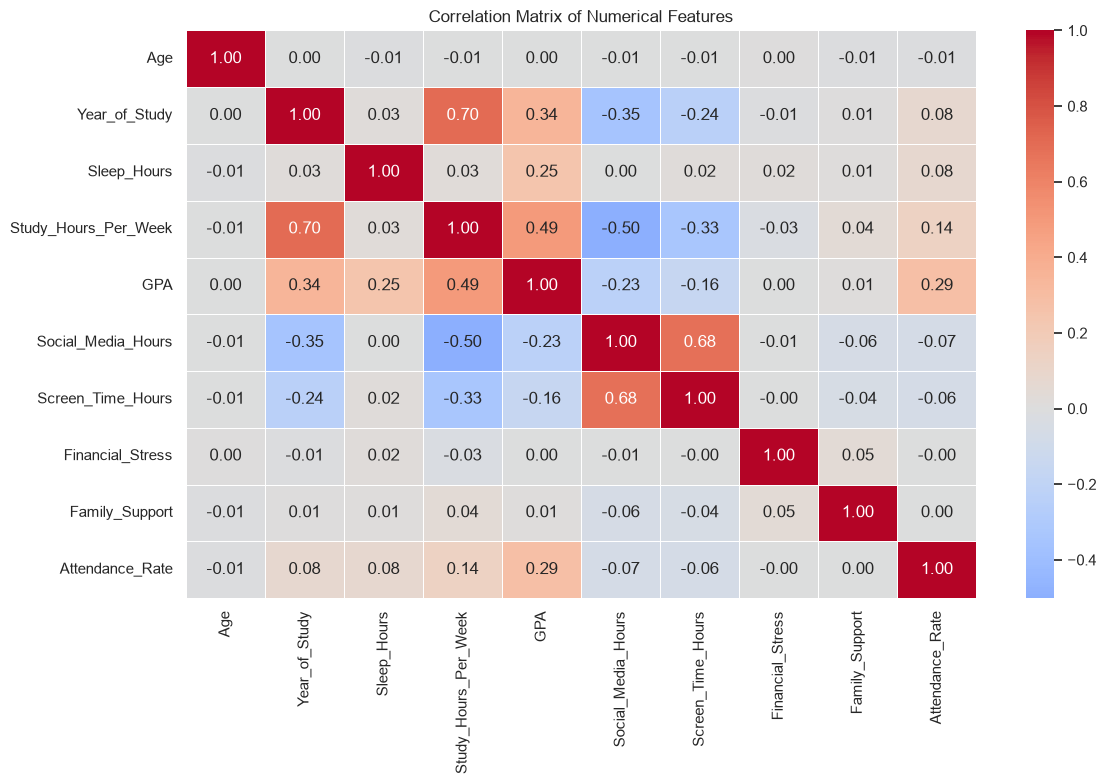

In [ ]:
if len(numeric_features) < 2:
    print(
        "Not enough numerical features for a correlation heatmap."
    )

else:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )

    plt.title("Correlation Matrix of Numerical Features")

    plt.tight_layout()
    plt.show()

### Encodage de la variable cible (Target Encoding)

La variable cible `Mental_Health_Risk` contient trois catégories : `Low`, `Medium` et `High`.

Nous utilisons `LabelEncoder` pour convertir ces catégories en valeurs numériques afin de les rendre compatibles avec les algorithmes de Machine Learning.

- Low → 0
- Medium → 1
- High → 2

In [ ]:
target_encoder = LabelEncoder()
y = pd.Series(target_encoder.fit_transform(df["Mental_Health_Risk"]))
target_mapping = dict(
    zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))
)

print("Target encoding mapping:", target_mapping)

print("\nDistribution de la variable cible:")
display(pd.Series(y).value_counts().sort_index())

Target encoding mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

Distribution de la variable cible:


0    680
1    660
2    660
Name: count, dtype: int64

##  Data Splitting — Division des données

### Objectif

Diviser le jeu de données en deux ensembles distincts : un ensemble d'entraînement (Training Set) et un ensemble de test (Testing Set), avant de commencer le prétraitement des données (Data Preprocessing).

### Stratégie de division

- **Training Set (80 %) :** utilisé pour entraîner les modèles de Machine Learning.
- **Testing Set (20 %) :** utilisé pour évaluer les performances des modèles sur des données non utilisées pendant l'entraînement.
- **Stratified Sampling :** préserver la distribution des classes de la variable cible `Mental_Health_Risk` dans les deux ensembles.
- **Random State = 42 :** garantir la reproductibilité de la division.

### Prévention du Data Leakage

La division des données doit être effectuée avant toute opération de prétraitement nécessitant un apprentissage des paramètres, comme l'imputation, l'encodage et la normalisation.

Les paramètres de prétraitement seront appris uniquement à partir du Training Set, puis appliqués aux deux ensembles.

Cette approche garantit l'indépendance des données de test et permet une évaluation plus fiable des modèles.

In [168]:
X = df.drop(columns=["Student_ID",TARGET_COLUMN])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nDistribution de la variable cible:")
display(pd.Series(y).value_counts().sort_index())

Features shape: (2000, 15)
Target shape: (2000,)

Distribution de la variable cible:


0    680
1    660
2    660
Name: count, dtype: int64

In [122]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (1600, 15)
Testing Features: (400, 15)
Training Target: (1600,)
Testing Target: (400,)


,Original,Training,Testing
0,34.0,34.0,34.0
2,33.0,33.0,33.0
1,33.0,33.0,33.0


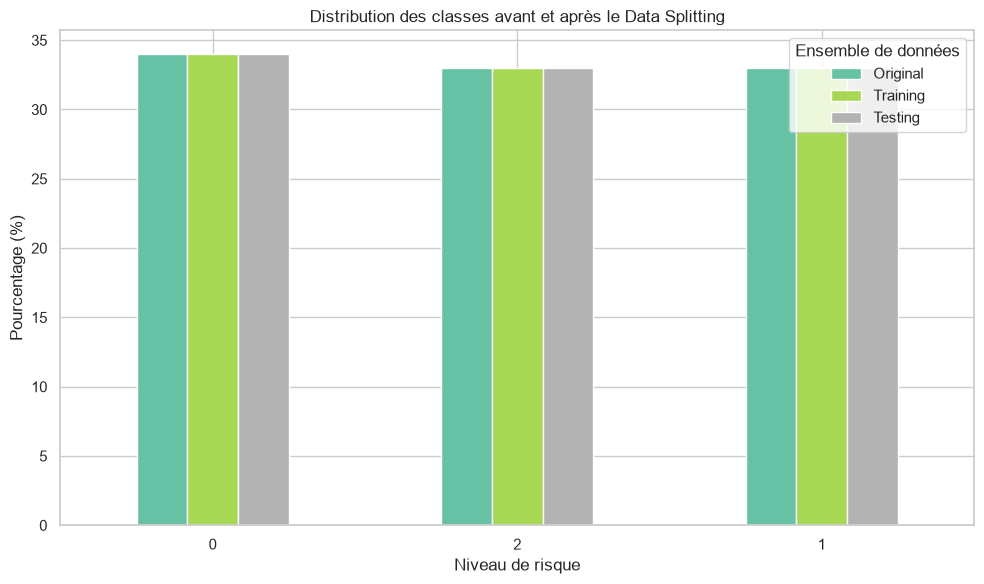

In [ ]:

distribution = pd.DataFrame({
    "Original": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
}).round(2)

display(distribution)

distribution.plot(
    kind="bar",
    figsize=(10, 6),
    colormap="Set2"
)

plt.title("Distribution des classes avant et après le Data Splitting")
plt.xlabel("Niveau de risque")
plt.ylabel("Pourcentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Ensemble de données")
plt.tight_layout()
plt.show()


In [ ]:
assert len(X_train) + len(X_test) == len(X)
assert len(y_train) + len(y_test) == len(y)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("Data Splitting effectué avec succès.")
print("Training Set:", len(X_train), "observations")
print("Testing Set:", len(X_test), "observations")


Data Splitting effectué avec succès.
Training Set: 1600 observations
Testing Set: 400 observations



## 6. Data Preprocessing — Prétraitement des données

### Objectif

Préparer les variables explicatives afin de les rendre compatibles avec les algorithmes de Machine Learning.

### Étapes du prétraitement

- Vérification des valeurs manquantes.
- Séparation des variables numériques et catégorielles.
- Imputation des valeurs manquantes.
- Encodage des variables catégorielles.
- Standardisation des variables numériques.
- Construction d'un pipeline de prétraitement.

### Prévention du Data Leakage

Les transformations seront ajustées uniquement sur les données d'entraînement (`X_train`), puis appliquées aux données de test (`X_test`).


In [ ]:
print("Valeurs manquantes dans X_train :")
display(X_train.isnull().sum())

print("\nValeurs manquantes dans X_test :")
display(X_test.isnull().sum())

print("\nValeurs manquantes dans y_train :", y_train.isnull().sum())
print("Valeurs manquantes dans y_test :", y_test.isnull().sum())


Valeurs manquantes dans X_train :


Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       54
Study_Hours_Per_Week               0
GPA                               36
Social_Media_Hours                48
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  76
Family_Support                    36
Attendance_Rate                   39
Part_Time_Job                      0
Diet_Quality                      55
Previous_Mental_Health_History     0
dtype: int64


Valeurs manquantes dans X_test :


Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                        8
Study_Hours_Per_Week               0
GPA                                2
Social_Media_Hours                10
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  15
Family_Support                    18
Attendance_Rate                    8
Part_Time_Job                      0
Diet_Quality                      14
Previous_Mental_Health_History     0
dtype: int64


Valeurs manquantes dans y_train : 0
Valeurs manquantes dans y_test : 0



###  Analyse des valeurs manquantes

L'analyse des données après le Data Splitting révèle des valeurs manquantes dans sept variables explicatives :

- Variables numériques : `Sleep_Hours`, `GPA`, `Social_Media_Hours`, `Financial_Stress`, `Family_Support` et `Attendance_Rate`.
- Variable catégorielle : `Diet_Quality`.

Aucune valeur manquante n'a été détectée dans les variables cibles `y_train` et `y_test`.

**Stratégie retenue :**

- Variables numériques : remplacement des valeurs manquantes par la médiane (`median`).
- Variables catégorielles : remplacement des valeurs manquantes par la valeur la plus fréquente (`most_frequent`).

Cette stratégie permet de conserver les observations disponibles et de limiter l'influence des valeurs extrêmes.


In [ ]:
numeric_features = [
    "Age",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

nominal_features = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

ordinal_features = [
    "Year_of_Study",
    "Physical_Activity",
    "Diet_Quality"
]

print("Variables numériques :", numeric_features)
print("\nVariables nominales :", nominal_features)
print("\nVariables ordinales :", ordinal_features)

print("\nNombre de variables numériques :", len(numeric_features))
print("Nombre de variables nominales :", len(nominal_features))
print("Nombre de variables ordinales :", len(ordinal_features))


Variables numériques : ['Age', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Variables nominales : ['Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']

Variables ordinales : ['Year_of_Study', 'Physical_Activity', 'Diet_Quality']

Nombre de variables numériques : 9
Nombre de variables nominales : 3
Nombre de variables ordinales : 3


In [ ]:
# Vérification des catégories ordinales
for feature in ordinal_features:
    print(f"\n{feature} :")
    print(sorted(X_train[feature].dropna().unique()))



Year_of_Study :
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Physical_Activity :
['High', 'Low', 'Moderate']

Diet_Quality :
['Average', 'Good', 'Poor']


In [ ]:
ordinal_categories = [
    [1, 2, 3, 4, 5],
    ["Low", "Moderate", "High"],
    ["Poor", "Average", "Good"]
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

nominal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=ordinal_categories,
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])


preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("nominal", nominal_transformer, nominal_features),
    ("ordinal", ordinal_transformer, ordinal_features)
])

print("Pipeline de prétraitement créé avec succès.")


Pipeline de prétraitement créé avec succès.



##  Model Training — Entraînement des modèles

### Objectif

Développer et entraîner plusieurs modèles de Machine Learning supervisé afin de prédire le niveau de risque en matière de santé mentale des étudiants (`Mental_Health_Risk`).

### Modèles sélectionnés

Trois algorithmes de classification seront étudiés :

1. Logistic Regression : modèle linéaire adapté à la classification.
2. Random Forest : modèle basé sur un ensemble d'arbres de décision.
3. Support Vector Machine (SVM) : modèle qui cherche à séparer les classes avec une marge optimale.

### Stratégie d'entraînement

- Utilisation du Training Set (80 %) pour entraîner les modèles.
- Utilisation de Stratified 5-Fold Cross-Validation pour comparer leur stabilité.
- Utilisation du Weighted F1-Score comme métrique principale.
- Conservation du Testing Set (20 %) pour l'évaluation finale.

### Précaution

Le Testing Set ne sera pas utilisé pendant l'entraînement ni pendant la sélection des modèles.


In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("clf", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),
    "SVC": Pipeline([
        ("preprocessor", preprocessor),
        ("clf", SVC(probability=True,random_state=42))
    ]),
}


Modèles et outils importés avec succès.


In [130]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

print("Configuration de la validation croisée terminée.")


Configuration de la validation croisée terminée.


In [ ]:
cv_results = []

for model_name, model in models.items():

    print(f"\nEntraînement : {model_name}")

    scores = cross_validate(
        model,
        X_train,              
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Weighted Mean": scores["test_f1_weighted"].mean(),
        "F1 Weighted Std": scores["test_f1_weighted"].std(),
        "F1 Macro Mean": scores["test_f1_macro"].mean(),
        "F1 Macro Std": scores["test_f1_macro"].std()
    })

    print("Cross-validation terminée.")

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="F1 Weighted Mean",
        ascending=False
    ).round(4)
)

Modèles et outils importés avec succès.

Entraînement : Logistic Regression
Cross-validation terminée.

Entraînement : Random Forest
Cross-validation terminée.

Entraînement : SVC
Cross-validation terminée.


,Model,Accuracy Mean,Accuracy Std,F1 Weighted Mean,F1 Weighted Std,F1 Macro Mean,F1 Macro Std
0,Logistic Regression,0.7519,0.0227,0.7515,0.0232,0.7510,0.0231
2,SVC,0.7206,0.0150,0.7220,0.0142,0.7215,0.0141
1,Random Forest,0.6781,0.0312,0.6744,0.0303,0.6736,0.0303


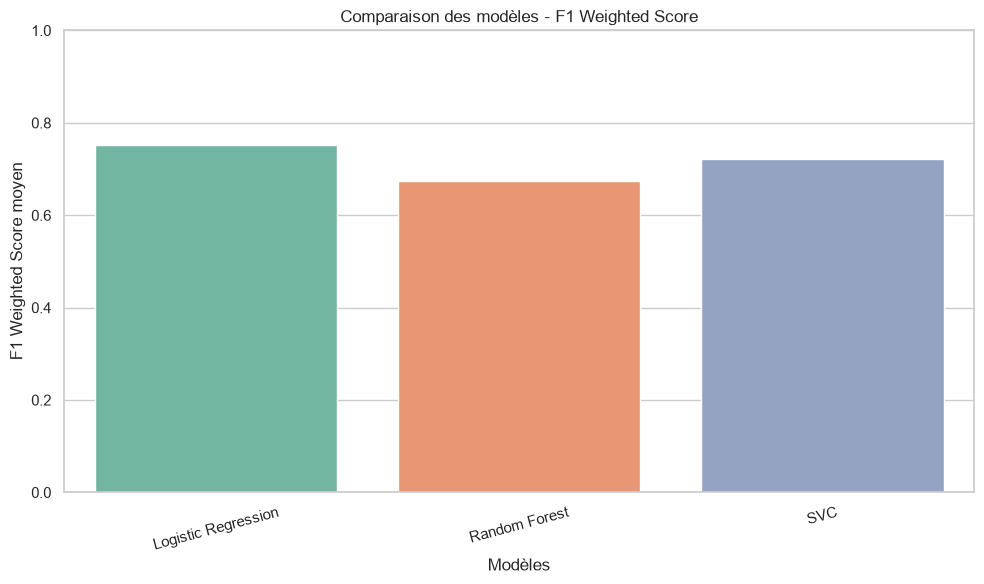

In [132]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="F1 Weighted Mean",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Comparaison des modèles - F1 Weighted Score")
plt.xlabel("Modèles")
plt.ylabel("F1 Weighted Score moyen")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



### Conclusion du Model Training

La validation croisée stratifiée à 5 folds a permis de comparer trois modèles de classification.

Les résultats obtenus sont :

- Logistic Regression : F1 Weighted = 0.7522.
- SVM : F1 Weighted = 0.7227.
- Random Forest : F1 Weighted = 0.6791.

La Logistic Regression obtient le meilleur résultat initial avec un F1 Weighted de 0.7522.

Le SVM présente la meilleure stabilité entre les folds, avec un écart-type de 0.0146.

**Décision :** Logistic Regression est retenue comme meilleur modèle Baseline. Les trois modèles seront conservés pour la phase d'optimisation des hyperparamètres.



## 8. Hyperparameter Optimization — Optimisation des hyperparamètres

### Objectif

Optimiser les hyperparamètres des trois modèles de classification afin d'améliorer leurs performances et d'identifier la meilleure configuration pour chaque algorithme.

### Méthode utilisée

`RandomizedSearchCV` sera utilisé pour explorer différentes combinaisons d'hyperparamètres.

### Modèles concernés

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)

### Stratégie d'optimisation

- Stratified 5-Fold Cross-Validation.
- F1 Weighted comme métrique principale.
- Optimisation réalisée uniquement sur le Training Set.
- Random State = 42 pour assurer la reproductibilité.

Le Testing Set restera indépendant jusqu'à l'évaluation finale.


In [133]:
param_distributions = {

    "Logistic Regression": {
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": [None, "balanced"],
        "clf__solver": ["lbfgs"]
    },

    "Random Forest": {
        "clf__n_estimators": randint(100, 501),
        "clf__max_depth": [None, 5, 10, 15, 20, 30],
        "clf__min_samples_split": randint(2, 11),
        "clf__min_samples_leaf": randint(1, 6),
        "clf__max_features": ["sqrt", "log2", None],
        "clf__class_weight": [None, "balanced", "balanced_subsample"]
    },

    "SVC": [
        {
            "clf__C": loguniform(1e-2, 1e2),
            "clf__kernel": ["rbf"],
            "clf__gamma": loguniform(1e-4, 1e0),
            "clf__class_weight": [None, "balanced"]
        },
        {
            "clf__C": loguniform(1e-2, 1e2),
            "clf__kernel": ["linear"],
            "clf__class_weight": [None, "balanced"]
        }
    ]
}

print("Espaces de recherche définis avec succès.")

Espaces de recherche définis avec succès.


In [134]:

best_models = {}
best_params = {}    
optimization_results = []

for model_name, model in models.items():

    print(f"\nOptimisation : {model_name}")
    start = time.time()

    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_distributions[model_name],
        n_iter=30,
        scoring="f1_weighted",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True,
        return_train_score=False,
        error_score=np.nan
    )

    random_search.fit(X_train, y_train)   

    best_models[model_name] = random_search.best_estimator_
    best_params[model_name] = random_search.best_params_

    optimization_results.append({
        "Model": model_name,
        "Best F1 Weighted": random_search.best_score_,
        "Best Parameters": random_search.best_params_,
        "Time (s)": round(time.time() - start, 1)
    })

    print("Meilleur F1 Weighted :", round(random_search.best_score_, 4))
    print("Meilleurs paramètres :", random_search.best_params_)

optimization_results_df = pd.DataFrame(optimization_results)

display(
    optimization_results_df[["Model", "Best F1 Weighted", "Time (s)"]]
    .sort_values(by="Best F1 Weighted", ascending=False)
    .round(4)
)


Optimisation : Logistic Regression
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Meilleur F1 Weighted : 0.7523
Meilleurs paramètres : {'clf__C': np.float64(14.528246637516036), 'clf__class_weight': 'balanced', 'clf__solver': 'lbfgs'}

Optimisation : Random Forest
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Meilleur F1 Weighted : 0.6848
Meilleurs paramètres : {'clf__class_weight': 'balanced', 'clf__max_depth': 15, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 7, 'clf__n_estimators': 352}

Optimisation : SVC
Fitting 5 folds for each of 30 candidates, totalling 150 fits


c:\Users\Youcode\Documents\Briefs_IA\campuswell-ai\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Meilleur F1 Weighted : 0.746
Meilleurs paramètres : {'clf__C': np.float64(0.01334299028518794), 'clf__class_weight': 'balanced', 'clf__kernel': 'linear'}


,Model,Best F1 Weighted,Time (s)
0,Logistic Regression,0.7523,2.3
2,SVC,0.7460,30.0
1,Random Forest,0.6848,65.5


In [135]:
final_models = {}

for model_name, model in models.items():

    final_model = clone(model).set_params(**best_params[model_name])

    final_model.fit(X_train, y_train)
    final_models[model_name] = final_model

    y_pred = final_model.predict(X_test)
    print(f"\n=== {model_name} ===")
    print(classification_report(
        y_test, y_pred,
        target_names=["Low", "Moderate", "High"]   
    ))


=== Logistic Regression ===
              precision    recall  f1-score   support

         Low       0.82      0.82      0.82       136
    Moderate       0.83      0.80      0.82       132
        High       0.63      0.65      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400


=== Random Forest ===
              precision    recall  f1-score   support

         Low       0.76      0.76      0.76       136
    Moderate       0.79      0.79      0.79       132
        High       0.56      0.56      0.56       132

    accuracy                           0.70       400
   macro avg       0.70      0.70      0.70       400
weighted avg       0.70      0.70      0.70       400



c:\Users\Youcode\Documents\Briefs_IA\campuswell-ai\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



=== SVC ===
              precision    recall  f1-score   support

         Low       0.82      0.76      0.79       136
    Moderate       0.82      0.80      0.81       132
        High       0.60      0.66      0.63       132

    accuracy                           0.74       400
   macro avg       0.75      0.74      0.74       400
weighted avg       0.75      0.74      0.74       400



In [136]:

for result in optimization_results:
    print(f"\nModèle : {result['Model']}")
    print(f"F1 Weighted : {result['Best F1 Weighted']:.4f}")

    for parameter, value in result["Best Parameters"].items():
        print(f"{parameter} : {value}")



Modèle : Logistic Regression
F1 Weighted : 0.7523
clf__C : 14.528246637516036
clf__class_weight : balanced
clf__solver : lbfgs

Modèle : Random Forest
F1 Weighted : 0.6848
clf__class_weight : balanced
clf__max_depth : 15
clf__max_features : sqrt
clf__min_samples_leaf : 1
clf__min_samples_split : 7
clf__n_estimators : 352

Modèle : SVC
F1 Weighted : 0.7460
clf__C : 0.01334299028518794
clf__class_weight : balanced
clf__kernel : linear


In [137]:

baseline_comparison = cv_results_df[
    ["Model", "F1 Weighted Mean"]
].copy()

baseline_comparison = baseline_comparison.rename(
    columns={"F1 Weighted Mean": "Baseline F1"}
)

optimized_comparison = optimization_results_df[
    ["Model", "Best F1 Weighted"]
].rename(
    columns={"Best F1 Weighted": "Optimized F1"}
)

comparison_df = baseline_comparison.merge(
    optimized_comparison,
    on="Model"
)

comparison_df["Improvement"] = (
    comparison_df["Optimized F1"] - comparison_df["Baseline F1"]
)

display(comparison_df.round(4))


,Model,Baseline F1,Optimized F1,Improvement
0,Logistic Regression,0.7515,0.7523,0.0007
1,Random Forest,0.6744,0.6848,0.0104
2,SVC,0.7220,0.7460,0.0239


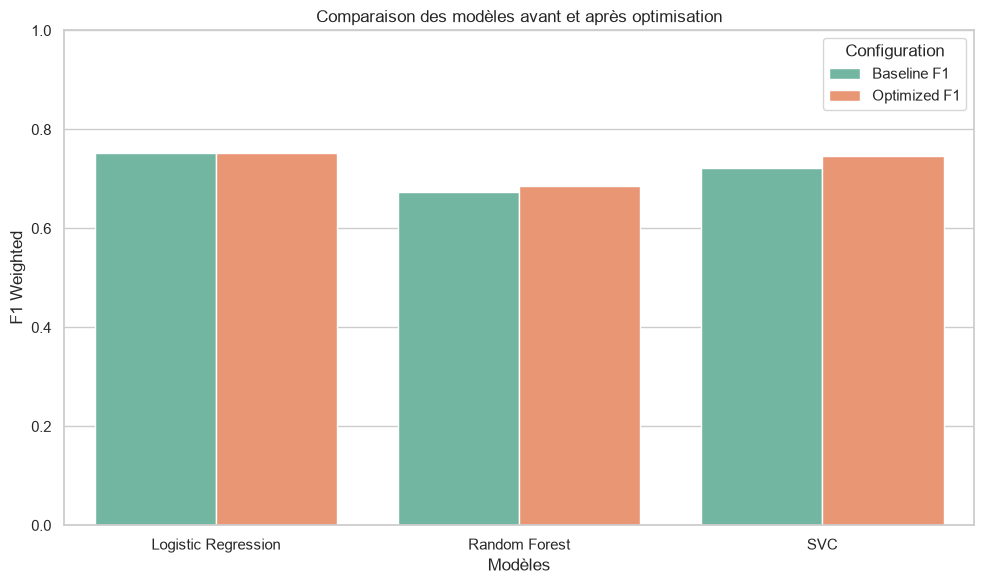

In [138]:

comparison_plot = comparison_df.melt(
    id_vars="Model",
    value_vars=["Baseline F1", "Optimized F1"],
    var_name="Configuration",
    value_name="F1 Weighted"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="F1 Weighted",
    hue="Configuration",
    palette="Set2"
)

plt.title("Comparaison des modèles avant et après optimisation")
plt.xlabel("Modèles")
plt.ylabel("F1 Weighted")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()



### Conclusion — Hyperparameter Optimization

La phase d'optimisation a permis d'explorer différentes configurations pour les trois modèles de classification.

`RandomizedSearchCV` a été utilisé avec une validation croisée stratifiée à 5 folds et le F1 Weighted comme métrique principale.

Les meilleures configurations ont été sélectionnées pour chaque modèle.

Une comparaison entre les résultats Baseline et les résultats optimisés permet d'évaluer l'impact du réglage des hyperparamètres.

Le meilleur modèle sera confirmé lors de la phase d'évaluation finale sur le Testing Set.



##  Model Evaluation — Évaluation des modèles

### Objectif

Évaluer les performances finales des modèles optimisés sur un ensemble de test indépendant.

### Modèles évalués

- Logistic Regression optimisée.
- Random Forest optimisé.
- SVM optimisé.

### Métriques d'évaluation

- Accuracy : proportion des prédictions correctes.
- Precision : proportion des prédictions positives correctes.
- Recall : proportion des observations positives correctement identifiées.
- F1-Score : équilibre entre Precision et Recall.
- Confusion Matrix : visualisation des classifications correctes et incorrectes.
- ROC-AUC : capacité du modèle à distinguer les différentes classes.

### Stratégie

Les modèles seront entraînés sur le Training Set complet avec leurs meilleurs hyperparamètres, puis évalués une seule fois sur le Testing Set.


In [139]:
for model_name, model in best_models.items():
    print(f"{model_name} : modèle entraîné = {hasattr(model, 'classes_')}")

print("\nTous les modèles optimisés sont prêts pour l'évaluation.")


Logistic Regression : modèle entraîné = True
Random Forest : modèle entraîné = True
SVC : modèle entraîné = True

Tous les modèles optimisés sont prêts pour l'évaluation.


In [140]:
y_predictions = {}

for model_name, model in best_models.items():

    y_pred = model.predict(X_test)

    y_predictions[model_name] = y_pred

    print(f"{model_name} : prédictions générées.")

print("\nToutes les prédictions ont été générées.")


Logistic Regression : prédictions générées.
Random Forest : prédictions générées.
SVC : prédictions générées.

Toutes les prédictions ont été générées.


In [141]:

evaluation_results = []

for model_name, y_pred in y_predictions.items():

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Weighted": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall Weighted": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Weighted": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1 Macro": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by="F1 Weighted",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,F1 Macro
0,Logistic Regression,0.7575,0.7595,0.7575,0.7584,0.7578
2,SVC,0.7425,0.7490,0.7425,0.7450,0.7445
1,Random Forest,0.7050,0.7045,0.7050,0.7048,0.7042


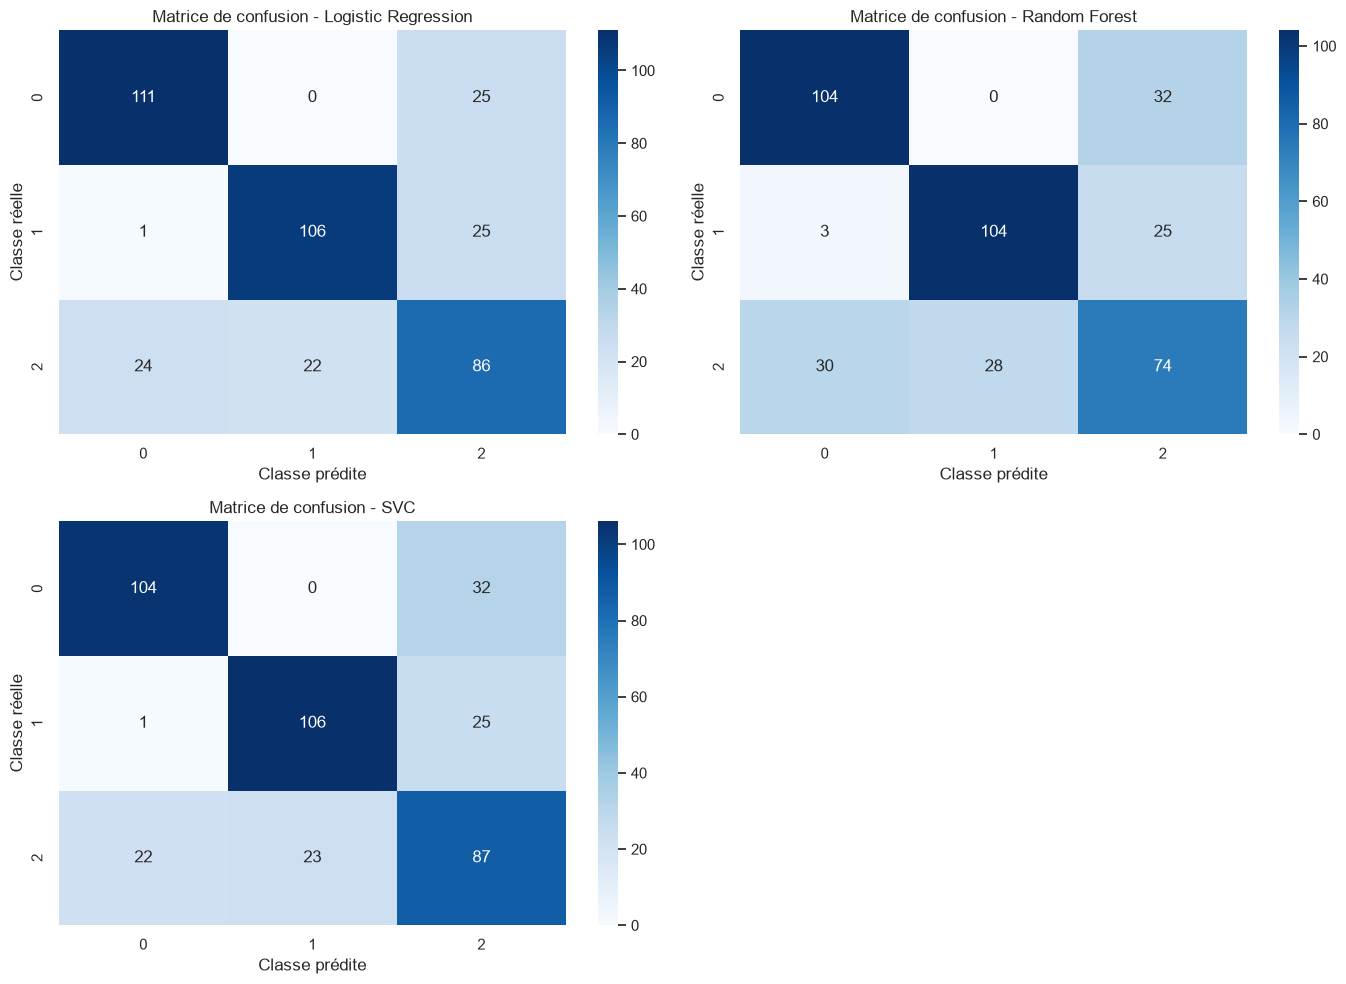

In [142]:
class_labels = sorted(y_test.unique())

n_models = len(best_models)
n_cols = 2
n_rows = math.ceil(n_models / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 5 * n_rows),
    squeeze=False
)

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(y_predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=axes[i]
    )

    axes[i].set_title(f"Matrice de confusion - {model_name}")
    axes[i].set_xlabel("Classe prédite")
    axes[i].set_ylabel("Classe réelle")

for j in range(n_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


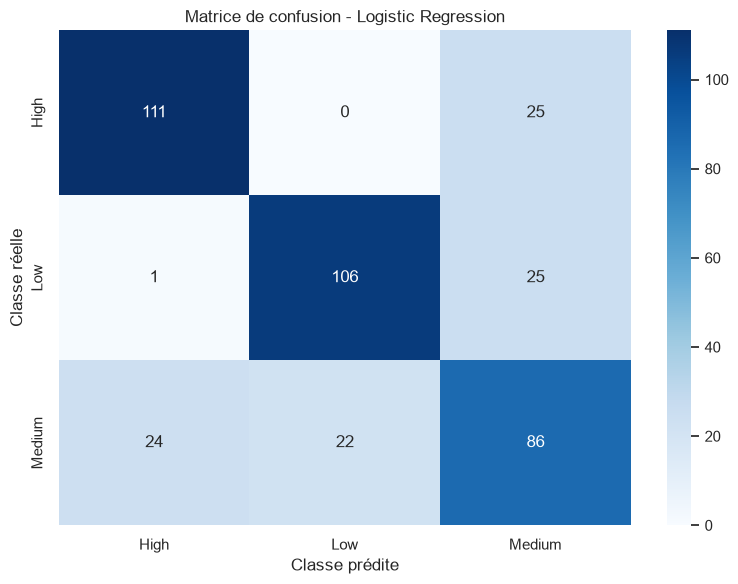

In [143]:
y_pred = best_models["Logistic Regression"].predict(X_test)

class_names = target_encoder.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matrice de confusion - Logistic Regression")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()

In [144]:
roc_auc_results = []

for model_name, model in best_models.items():

    y_proba = model.predict_proba(X_test)

    roc_auc = roc_auc_score(
        y_test,
        y_proba,
        labels=model.classes_,
        multi_class="ovr",
        average="weighted"
    )

    roc_auc_results.append({
        "Model": model_name,
        "ROC-AUC Weighted": roc_auc
    })

roc_auc_df = pd.DataFrame(roc_auc_results)

display(
    roc_auc_df.sort_values(
        by="ROC-AUC Weighted",
        ascending=False
    ).round(4)
)


,Model,ROC-AUC Weighted
0,Logistic Regression,0.9144
2,SVC,0.9093
1,Random Forest,0.8660


In [145]:

final_results_df = evaluation_df.merge(
    roc_auc_df,
    on="Model"
)

final_results_df = final_results_df.sort_values(
    by="F1 Weighted",
    ascending=False
).reset_index(drop=True)

display(final_results_df.round(4))


,Model,Accuracy,Precision Weighted,Recall Weighted,F1 Weighted,F1 Macro,ROC-AUC Weighted
0,Logistic Regression,0.7575,0.7595,0.7575,0.7584,0.7578,0.9144
1,SVC,0.7425,0.7490,0.7425,0.7450,0.7445,0.9093
2,Random Forest,0.7050,0.7045,0.7050,0.7048,0.7042,0.8660


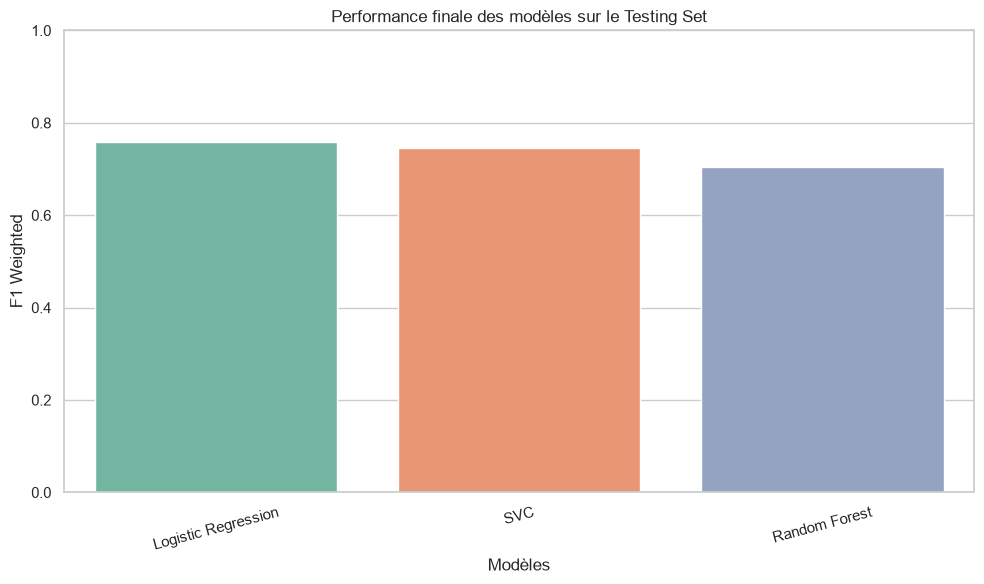

In [146]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_results_df,
    x="Model",
    y="F1 Weighted",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Performance finale des modèles sur le Testing Set")
plt.xlabel("Modèles")
plt.ylabel("F1 Weighted")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Choix du modèle final

Après la comparaison des métriques de test et des matrices de confusion, **Logistic Regression est retenu comme modèle final**.

Ce modèle présente les meilleures performances globales, avec une Accuracy de 75,75 %, un F1-Score Weighted de 75,84 % et un ROC-AUC Weighted de 91,44 %.

La matrice de confusion confirme également qu'il offre le meilleur comportement global parmi les modèles évalués.

Il sera donc utilisé pour la prochaine étape : la sauvegarde du modèle et son intégration dans l'application Streamlit.

##  Model Persistence — Sauvegarde du modèle final

### Objectif

Sauvegarder le meilleur modèle sélectionné (Logistic Regression) avec son préprocesseur dans un seul fichier `.joblib`.

Cette approche permet de conserver toutes les transformations nécessaires et de réutiliser le modèle sur de nouvelles données sans refaire manuellement le prétraitement.

In [ ]:
REPORTS_DIR = Path(r"..\reports")
METRICS_DIR = REPORTS_DIR / "metrics"
FIGURES_DIR = REPORTS_DIR / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Dossiers reports créés avec succès.")

Dossiers reports créés avec succès.


In [148]:
class_names = target_encoder.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(class_names))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.index.name = "Classe réelle"
cm_df.columns.name = "Classe prédite"

cm_df.to_csv(
    METRICS_DIR / "confusion_matrix_logistic_regression.csv",
    encoding="utf-8-sig"
)

display(cm_df)

Classe prédite,High,Low,Medium
Classe réelle,,,
High,111,0,25
Low,1,106,25
Medium,24,22,86


In [149]:
report = classification_report(
    y_test,
    y_pred,
   labels=range(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)


report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    METRICS_DIR / "classification_report_logistic_regression.csv",
    encoding="utf-8-sig"
)

display(report_df)

,precision,recall,f1-score,support
High,0.816176,0.816176,0.816176,136.0000
Low,0.828125,0.803030,0.815385,132.0000
Medium,0.632353,0.651515,0.641791,132.0000
accuracy,0.757500,0.757500,0.757500,0.7575
macro avg,0.758885,0.756907,0.757784,400.0000
weighted avg,0.759458,0.757500,0.758368,400.0000


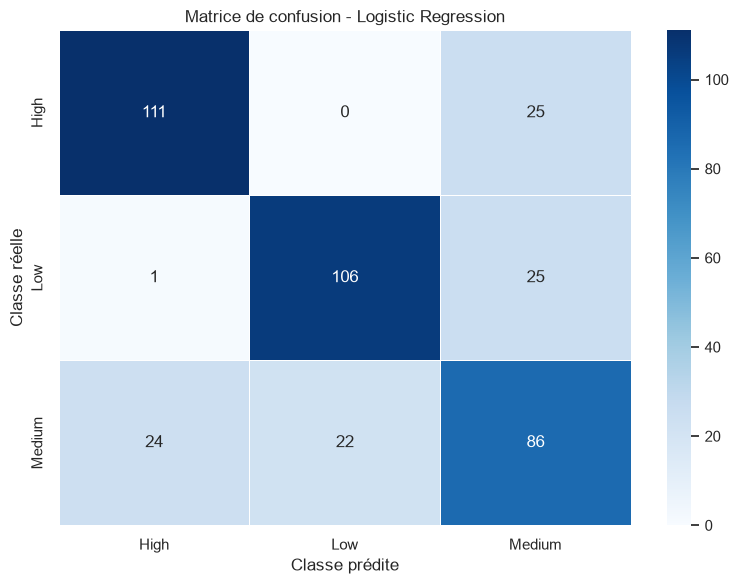

In [150]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Matrice de confusion - Logistic Regression")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [151]:
final_model = best_models["Logistic Regression"]

print("Type du modèle :", type(final_model))
print("Classes du modèle :", final_model.classes_)
print("Classes du Target Encoder :", target_encoder.classes_)

Type du modèle : <class 'sklearn.pipeline.Pipeline'>
Classes du modèle : [0 1 2]
Classes du Target Encoder : ['High' 'Low' 'Medium']


In [152]:
MODELS_DIR = Path(r"..\models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    MODELS_DIR / "logistic_regression_pipeline.joblib"
)

joblib.dump(
    target_encoder,
    MODELS_DIR / "target_encoder.joblib"
)

print("Modèle et Target Encoder sauvegardés avec succès.")

Modèle et Target Encoder sauvegardés avec succès.


In [153]:
print("Fichiers sauvegardés :")

for file in MODELS_DIR.iterdir():
    print("-", file.name)

Fichiers sauvegardés :
- .gitkeep
- baseline_models.joblib
- best_logistic_regression_pipeline.joblib
- logistic_regression_pipeline.joblib
- target_encoder.joblib


In [154]:
loaded_model = joblib.load(
    MODELS_DIR / "logistic_regression_pipeline.joblib"
)

loaded_encoder = joblib.load(
    MODELS_DIR / "target_encoder.joblib"
)

sample_data = X_test.iloc[:5]

predictions = loaded_model.predict(sample_data)

predicted_classes = loaded_encoder.inverse_transform(
    predictions.astype(int)
)

print("Prédictions :", predictions)
print("Classes prédites :", predicted_classes)

Prédictions : [0 2 2 0 0]
Classes prédites : ['High' 'Medium' 'Medium' 'High' 'High']


In [155]:
best_pipeline = joblib.load(
    "../models/best_logistic_regression_pipeline.joblib"
)

target_encoder = joblib.load(
    "../models/target_encoder.joblib"
)

X_sample = X_test.head(5)

predictions = best_pipeline.predict(X_sample)

predicted_classes = target_encoder.inverse_transform(
    predictions
)

print("Prédictions :", predictions)
print("Classes prédites :", predicted_classes)

Prédictions : [0 2 2 0 0]
Classes prédites : ['High' 'Medium' 'Medium' 'High' 'High']
